In [1]:
import json, sys, time
from pathlib import Path

REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(REPO))

from dotenv import load_dotenv
load_dotenv(REPO / ".env")

%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from PIL import Image
from torch.utils.data import DataLoader
from tqdm.auto import tqdm

from ml.config import data_root
from ml.datasets.targets import NIH_FINDINGS
from ml.evaluation.calibration import apply_platt
from ml.inference.screener import Screener, band
from ml.training.data import XrayDataset, load_processed
from ml.training.train import predict

ROOT = data_root()
screener = Screener.load(REPO)
for m in screener.models:
    print(f"{m.name}: {'loaded' if m.model is not None else m.error} | device {screener.device}")

nih_densenet121_v1: loaded | device cuda
tb_densenet121_v2: loaded | device cuda


In [3]:
nih = load_processed(ROOT, "nih")
check = pd.concat([nih[nih["split"] == "test"].sample(150, random_state=0).assign(set="nih_test"),
                   load_processed(ROOT, "montgomery").sample(50, random_state=0).assign(set="montgomery"),
                   load_processed(ROOT, "shenzhen").sample(50, random_state=0).assign(set="shenzhen")],
                  ignore_index=True)

# reference = the evaluation path: stored 320 px PNG -> DataLoader -> predict -> Platt from the config files
ref = {}
for m in screener.models:
    raw = predict(m.model, DataLoader(XrayDataset(check, ROOT, []), batch_size=32), screener.device)
    ref[m.name] = np.stack([apply_platt(raw[:, i], m.calibration[f]["platt_a"], m.calibration[f]["platt_b"])
                            for i, f in enumerate(m.findings)], axis=1)
ref = np.concatenate([ref[m.name] for m in screener.models], axis=1)
pairs = [(m, f) for m in screener.models for f in m.findings]
names = [f for _, f in pairs]

rows, times = [], []
for r in tqdm(check.itertuples(), total=len(check), desc="screen() from raw files"):
    t0 = time.perf_counter()
    res = screener.screen(ROOT / r.raw_path, explain=False)
    times.append(time.perf_counter() - t0)
    stored = np.asarray(Image.open(ROOT / r.processed_path))
    rows.append({"set": r.set, "image_id": r.image_id, "status": res.status,
                 "same_pixels": res.image is not None and np.array_equal(res.image, stored),
                 **{f"s_{f}": res.finding(f).score for f in names}, **{f"b_{f}": res.finding(f).band for f in names}})
got = pd.DataFrame(rows)
mine = got[[f"s_{f}" for f in names]].to_numpy(dtype=float)
diff = np.abs(mine - ref)
ref_band = np.array([[band(v, m.calibration[f]) for v, (m, f) in zip(row, pairs)] for row in ref], dtype=object)
same_band = (got[[f"b_{f}" for f in names]].to_numpy() == ref_band)

print(f"images {len(got)} | status ok {(got['status'] == 'success').mean():.1%} | "
      f"identical preprocessing {got['same_pixels'].mean():.1%}")
print(f"score difference vs evaluation pipeline: max {np.nanmax(diff):.5f} | median {np.nanmedian(diff):.6f}")
print(f"same band {same_band.mean():.2%} ({(~same_band).sum()} of {same_band.size} finding results differ)")
saved = pd.read_csv(REPO / "ml" / "checkpoints" / "nih_densenet121_v1" / "test_predictions.csv").set_index("image_id")
nt = got[got["set"] == "nih_test"]
d_saved = np.abs(nt[[f"s_{f}" for f in NIH_FINDINGS]].to_numpy(dtype=float)
                 - saved.loc[nt["image_id"], [f"cal_{f.lower()}" for f in NIH_FINDINGS]].to_numpy(dtype=float))
print(f"NIH vs saved test_predictions.csv: max difference {d_saved.max():.5f}")
print(f"time per image without heatmaps: median {np.median(times) * 1000:.0f} ms")
ok = got["same_pixels"].mean() > 0.99 and np.nanmax(diff) < 0.005 and same_band.mean() > 0.995 and d_saved.max() < 0.005
print("PARITY", "PASS " if ok else "CHECK ❗ send me this output")

screen() from raw files:   0%|          | 0/250 [00:00<?, ?it/s]

images 250 | status ok 100.0% | identical preprocessing 100.0%
score difference vs evaluation pipeline: max 0.00071 | median 0.000002
same band 99.95% (2 of 3750 finding results differ)
NIH vs saved test_predictions.csv: max difference 0.00071
time per image without heatmaps: median 111 ms
PARITY PASS 


montgomery:MCUCXR_0352_1.png | status success | total 2.08 s | stages {'input': 'success', 'nih_densenet121_v1': 'success', 'explain:nih_densenet121_v1': 'success', 'tb_densenet121_v2': 'success', 'explain:tb_densenet121_v2': 'skipped'}


,display_name,group,score,band,heatmap,heatmap_peak
0,Atelectasis,Lung tissue,0.035,unlikely,below_possible,NaN
1,Cardiomegaly,Heart and other,0.016,possible,shown,0.473
2,Consolidation,Infection,0.006,unlikely,below_possible,NaN
3,Edema,Lung tissue,0.001,unlikely,below_possible,NaN
4,Effusion,Pleura,0.021,unlikely,below_possible,NaN
5,Emphysema,Lung tissue,0.001,unlikely,below_possible,NaN
6,Fibrosis,Lung tissue,0.004,unlikely,below_possible,NaN
7,Hernia,Heart and other,0.003,NaN,no_band,NaN
8,Infiltration,Infection,0.055,unlikely,below_possible,NaN
9,Mass,Lung tissue,0.046,possible,shown,0.464


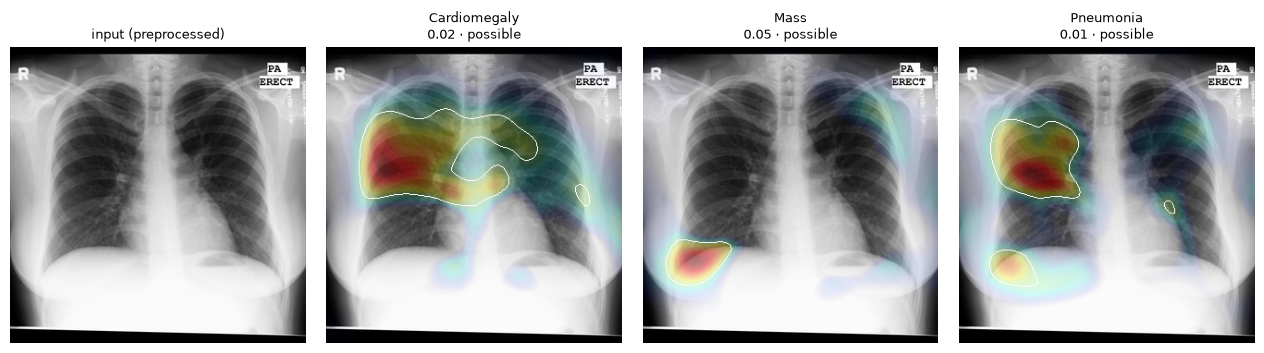

{
 "status": "success",
 "error": null,
 "findings": [
  {
   "finding": "Atelectasis",
   "display_name": "Atelectasis",
   "group": "Lung tissue",
   "model": "nih_densenet121_v1",
   "status": "success",
   "score": 0.034956,
   "band": "unlikely",
   "band_status": "banded",
   "possible_threshold": 0.055352,
   "likely_threshold": 0.22156,
   "heatmap": "below_possible",
   "heatmap_peak": null
  },
  {
   "finding": "Cardiomegaly",
   "display_name": "Cardiomegaly",
   "group": "Heart and other",
   "model": "nih_densenet121_v1",
   "status": "success",
   "score": 0.015688,
   "band": "possible",
   "band_status": "banded",
   "possible_threshold": 0.013391,
   "likely_threshold": 0.041022,
   "heatmap": "shown",
   "heatmap_peak": 0.472835
  },
  {
   "finding": "Consolidation",
   "display_name": "Consolidation",
   "group": "Infection",
   "model": "nih_densenet121_v1",
   "status": "success",
   "score": 0.005697,
   "band": "unlikely",
   "band_status": "banded",
   "possib

In [4]:
mg = load_processed(ROOT, "montgomery")
pos = mg[mg["label_tuberculosis"] == 1].sample(1, random_state=3).iloc[0]
t0 = time.perf_counter()
res = screener.screen(ROOT / pos.raw_path)
print(f"{pos.image_id} | status {res.status} | total {(time.perf_counter() - t0):.2f} s | stages {res.stages}")
if res.errors:
    print("errors", res.errors)
table = pd.DataFrame([vars(f) for f in res.findings])[["display_name", "group", "score", "band", "heatmap", "heatmap_peak"]]
display(table.round(3))
shown = list(res.maps)
fig, axes = plt.subplots(1, len(shown) + 1, figsize=(3.2 * (len(shown) + 1), 3.4), squeeze=False)
axes[0, 0].imshow(res.image, cmap="gray"); axes[0, 0].set_title("input (preprocessed)", fontsize=9)
for ax, f in zip(axes[0, 1:], shown):
    r = res.finding(f)
    ax.imshow(res.overlay(f)); ax.set_title(f"{r.display_name}\n{r.score:.2f} · {r.band}", fontsize=9)
for ax in axes[0]:
    ax.axis("off")
plt.tight_layout(); plt.show()
print(json.dumps(res.to_dict(), indent=1)[:1500], "...")